# IEEE 14 bus

Reseau de test **IEEE 14 bus** : deux generateurs (bus 1 et 2), trois
compensateurs synchrones (bus 3, 6 et 8), onze charges. Les compensateurs sont
representes par des machines synchrones a puissance active nulle.

Les donnees sont sur une base de tension unique (100 kV) pour conserver les
valeurs en pu de MATPOWER. Les trois transformateurs a prise (4-7, 4-9 et 5-6,
rapports 0,978, 0,969 et 0,932) sont dans `T_Transfos`, avec leur rapport
(`U1_V / U2_V` = la prise, R et X en pu systeme) ; les deux autres branches
sans resistance (7-8, 7-9) restent des lignes. Toutes gardent R = 1e-4 pu, la ou
MATPOWER a R = 0 : sans cela le courant de branche donne un pole non amorti
(Re = -1e-4 1/s). Jusqu'au 2026-10-25 les prises etaient ignorees : le load flow
s'ecartait de `case14` de 1,6e-2 pu ; il s'en ecarte maintenant de 7e-5 pu
(voir le shunt du bus 4 ci-dessous).

> **Charges a Q negatif.** Une charge R-L ne peut pas consommer de reactif
> negatif : son inductance serait negative et ses poles instables. Le shunt de
> 19 Mvar du bus 9 est donc declare dans `T_Shunts`, comme dans MATPOWER, avec
> sa charge de 16,6 Mvar. Le bus 4, dont la demande reactive vaut -3,9 Mvar,
> recoit une charge de 1 % de P (0,478 Mvar) et un shunt qui ramene le total a
> -3,9 Mvar. `IEEE14.m` garde, lui, des charges a Q negatif. Ce shunt de
> 0,04378 pu n'est donc **pas** une donnee de MATPOWER (dont seul le bus 9 porte
> un shunt) : a admittance constante, il ramene la demande a -3,9 Mvar a 1 pu
> seulement, et a -4,06 Mvar a V4 = 1,018 pu ; c'est la source des 7e-5 pu
> restants.

```
  G1 - 1 -- 2 - G2          compensateurs synchrones aux bus 3, 6 et 8
       |  \  |  \
       5 -- 4 -- 3
       |    |  \
       6 -- 7 -- 8
     / | \  |
   11 12 13 9 -- 10, 14
```

Base systeme : **100 MVA, 60 Hz**, base de tension unique 100 kV.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/IEEE14.m`.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "IEEE14"
F_ZOOM = 5.0

f0 = 60.0
Sb = 100e6

Ub = 100e3  # base de tension unique : les valeurs pu de MATPOWER sont conservees

# BusType : 1 = slack, 2 = PV, 3 = PQ

Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,   Pg_W, Qg_var,     Pl_W,   Ql_var]
        ( 1, 1, Ub, 1.060, 0,    0, 0,      0,       0),
        ( 2, 2, Ub, 1.045, 0, 40e6, 0, 21.7e6,  12.7e6),
        ( 3, 2, Ub, 1.010, 0,    0, 0, 94.2e6,  19.0e6),
        ( 4, 3, Ub, 1.019, 0,    0, 0, 47.8e6, 0.478e6),
        ( 5, 3, Ub, 1.020, 0,    0, 0,  7.6e6,   1.6e6),
        ( 6, 2, Ub, 1.070, 0,    0, 0, 11.2e6,   7.5e6),
        ( 7, 3, Ub, 1.062, 0,    0, 0,      0,       0),
        ( 8, 2, Ub, 1.090, 0,    0, 0,      0,       0),
        ( 9, 3, Ub, 1.056, 0,    0, 0, 29.5e6,  16.6e6),
        (10, 3, Ub, 1.051, 0,    0, 0,  9.0e6,   5.8e6),
        (11, 3, Ub, 1.057, 0,    0, 0,  3.5e6,   1.8e6),
        (12, 3, Ub, 1.055, 0,    0, 0,  6.1e6,   1.6e6),
        (13, 3, Ub, 1.050, 0,    0, 0, 13.5e6,   5.8e6),
        (14, 3, Ub, 1.036, 0,    0, 0, 14.9e6,   5.0e6),
]

# T_Lines_SI : [ID, From, To, Length_km, R_ohm/km, X_ohm/km, B_S/km]
T_Lines_SI = []

# T_Lines_pu : [ID, From, To, Length_km, R_pu, X_pu, B_pu, Un_V, Sb_VA]
#   R_pu, X_pu, B_pu : valeurs TOTALES de la ligne, en pu sur (Un_V, Sb_VA)
T_Lines_pu = [
    ( 1,  1,  2, 1, 0.01938, 0.05917, 0.0528, Ub, 100e6),
    ( 2,  1,  5, 1, 0.05403, 0.22304, 0.0492, Ub, 100e6),
    ( 3,  2,  3, 1, 0.04699, 0.19797, 0.0438, Ub, 100e6),
    ( 4,  2,  4, 1, 0.05811, 0.17632, 0.0340, Ub, 100e6),
    ( 5,  2,  5, 1, 0.05695, 0.17388, 0.0346, Ub, 100e6),
    ( 6,  3,  4, 1, 0.06701, 0.17103, 0.0128, Ub, 100e6),
    ( 7,  4,  5, 1, 0.01335, 0.04211, 0.0000, Ub, 100e6),
    (11,  6, 11, 1, 0.09498, 0.19890, 0.0000, Ub, 100e6),
    (12,  6, 12, 1, 0.12291, 0.25581, 0.0000, Ub, 100e6),
    (13,  6, 13, 1, 0.06615, 0.13027, 0.0000, Ub, 100e6),
    (14,  7,  8, 1, 0.00010, 0.17615, 0.0000, Ub, 100e6),
    (15,  7,  9, 1, 0.00010, 0.11001, 0.0000, Ub, 100e6),
    (16,  9, 10, 1, 0.03181, 0.08450, 0.0000, Ub, 100e6),
    (17,  9, 14, 1, 0.12711, 0.27038, 0.0000, Ub, 100e6),
    (18, 10, 11, 1, 0.08205, 0.19207, 0.0000, Ub, 100e6),
    (19, 12, 13, 1, 0.22092, 0.19988, 0.0000, Ub, 100e6),
    (20, 13, 14, 1, 0.17093, 0.34802, 0.0000, Ub, 100e6),
]

# T_Shunts : [ID, BusID, B_pu]   (compensation shunt propre au bus)
T_Shunts = [
    (1, 4, 0.04378),
    (2, 9,    0.19),
]

# T_Transfos : [ID, From, To, Sn_VA, U1_V, U2_V, R_pu, X_pu]
#   R_pu, X_pu en pu sur (Sn_VA, U1_V), ramenes a la base systeme a l'assemblage
T_Transfos = [
    (1, 4, 7, 100e6, Ub, Ub/0.978, 0.0001, 0.20912),
    (2, 4, 9, 100e6, Ub, Ub/0.969, 0.0001, 0.55618),
    (3, 5, 6, 100e6, Ub, Ub/0.932, 0.0001, 0.25202),
]

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = []

# T_SMs : [ID, BusID, Sn_VA]  ou  [ID, BusID, Sn_VA, Rt_pu, Xt_pu]
T_SMs = [
    (1, 1, 332e6),
    (2, 2, 140e6),
    (3, 3, 100e6),
    (4, 6, 100e6),
    (5, 8, 100e6),
]
SM_PARAMS = {}

# T_GFM1s a T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFM1s = []
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []

# T_GFL1s, T_GFL2s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFL1s = []
T_GFL2s = []

# T_Loads : [ID, BusID, P_W, Q_var, Type]   (charges SPECIALES)
#   Type : 'I' = courant constant, 'P' = puissance constante. Les charges
#   classiques (R-L) viennent des colonnes Pl_W, Ql_var de Y_DER ; une charge
#   speciale s'y ajoute, load flow compris. Exemple : (1, 7, 0.5e6, 0.1e6, 'P'),
T_Loads = []

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

IEEE14 : 14 bus, 17 ligne(s), 3 transfo(s), 0 bus infini, 5 machine(s), 0 GFM, 0 GFL, 11 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 5 iterations (mismatch 1.60e-14)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0600       0.0000       2.4240      -0.1765
   2     1.0450      -5.1971       0.1830       0.3393
   3     1.0100     -13.0838      -0.9420       0.0689
   4     1.0162     -10.7713      -0.4780      -0.0048
   5     1.0180      -9.1968      -0.0760      -0.0160
   6     1.0700     -15.1743      -0.1120       0.0687
   7     1.0606     -14.1919       0.0000      -0.0000
   8     1.0900     -14.2966      -0.0000       0.1817
   9     1.0550     -15.8324      -0.2950      -0.1660
  10     1.0498     -16.0614      -0.0900      -0.0580
  11     1.0558     -15.8045      -0.0350      -0.0180
  12     1.0539     -16.1455      -0.0610      -0.0160
  13     1.0493     -16.1990      -0.1350      -0.0580
  14     1.0338     -17.0804      -0.1490      -0.0500

Somme des injections : P = +0.2340 pu, Q = +0.0954 pu  (= per

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 181 etats, 33 entrees, 154 sorties | max Re(lambda)=+8.260e-13>

181 etats, 33 entrees, 154 sorties
stable : True   max Re(lambda) = +8.2597e-13

Etats par element :
  bus1           2 : vd, vq
  bus2           2 : vd, vq
  bus3           2 : vd, vq
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus9           2 : vd, vq
  L1_1_2         2 : i_d, i_q
  L2_1_5         2 : i_d, i_q
  L3_2_3         2 : i_d, i_q
  L4_2_4         2 : i_d, i_q
  L5_2_5         2 : i_d, i_q
  L6_3_4         2 : i_d, i_q
  L7_4_5         2 : i_d, i_q
  L11_6_11       2 : i_d, i_q
  L12_6_12       2 : i_d, i_q
  L13_6_13       2 : i_d, i_q
  L14_7_8        2 : i_d, i_q
  L15_7_9        2 : i_d, i_q
  L16_9_10       2 : i_d, i_q
  L17_9_14       2 : i_d, i_q
  L18_10_11      2 : i_d, i_q
  L19_12_13      2 : i_d, i_q
  L20_13_14      2 : i_d, i_q
  T1_4_7         2 : i_d, i_q
  T2_4_9         2 : i_d, i_q
  T3_5_6         2 : i_d, i_q
  SM1           17 : phi_d, phi_q, phi_fd, phi_1d, phi

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
116,7.844244e-13,0.000000,1.248450e-13,0.000000,0.000000,SM1.theta,40.937842,SM2.theta,18.314913,SM3.theta,14.022540
92,-1.294389e-01,376.991118,6.000000e+01,60.000000,0.034335,T2_4_9.i_d,31.695280,T2_4_9.i_q,31.694752,T1_4_7.i_q,12.040586
93,-1.294389e-01,-376.991118,6.000000e+01,60.000000,0.034335,T2_4_9.i_d,31.695280,T2_4_9.i_q,31.694752,T1_4_7.i_q,12.040586
154,-1.817467e-01,0.000000,2.892589e-02,0.000000,100.000000,SM3.vpss,35.479569,SM6.vpss,23.292091,SM1.vpss,15.982093
157,-1.853067e-01,0.000000,2.949248e-02,0.000000,100.000000,SM8.vpss,89.481544,SM6.vpss,5.145135,SM3.vpss,4.887661
...,...,...,...,...,...,...,...,...,...,...,...
3,-7.464767e+05,-375.073557,1.188055e+05,59.694811,99.999987,L16_9_10.i_q,16.736601,L16_9_10.i_d,16.635296,L18_10_11.i_q,16.460787
4,-7.757843e+05,318.105132,1.234699e+05,50.628004,99.999992,L15_7_9.i_d,20.736715,L15_7_9.i_q,20.701240,L14_7_8.i_q,18.070388
5,-7.757843e+05,-318.105132,1.234699e+05,50.628004,99.999992,L15_7_9.i_d,20.736715,L15_7_9.i_q,20.701240,L14_7_8.i_q,18.070388


### 2.2 Carte des valeurs propres

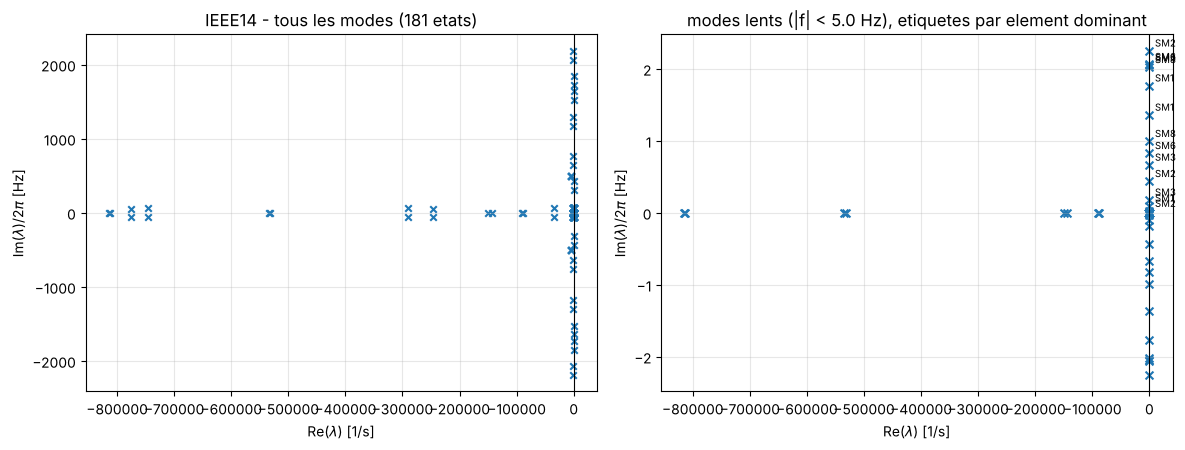

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()